In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Conv2D,Activation,Dropout,Flatten,MaxPooling2D
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.metrics import confusion_matrix

I0000 00:00:1794207821.135331    9649 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794207821.393725    9649 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794207823.176699    9649 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
dataset_path = "/home/lokesh/Loki/Projects/GEN AI/Face mask detection/dataset"

In [3]:
X = []
y = []
categories = ["with_mask", "without_mask"]
for label, category in enumerate(categories):
    folder_path = os.path.join(dataset_path, category)
    for image_name in os.listdir(folder_path):
        image_path = os.path.join(folder_path, image_name)
        try:
            image = keras.utils.load_img( image_path, target_size=(128,128) )
            image = keras.utils.img_to_array(image)
            X.append(image)
            y.append(label)
        except Exception as e:
            print("Skipping:", image_name)

/home/lokesh/Loki/Projects/GEN AI/.venv/lib/python3.14/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [4]:
X = np.array(X)
y = np.array(y)

In [5]:
print(X.shape)
print(y.shape)

(3846, 128, 128, 3)
(3846,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y )

In [7]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [8]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(3076, 128, 128, 3)
(770, 128, 128, 3)
(3076,)
(770,)


In [9]:
model = Sequential()
model.add(Conv2D(28,kernel_size=(3,3),input_shape=(128,128,3),activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))

/home/lokesh/Loki/Projects/GEN AI/.venv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1794207832.200292    9649 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [10]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [11]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [12]:
history = model.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=15,
    validation_data=(X_test, y_test),
    callbacks=[early_stop]
)

W0000 00:00:1794207832.834004    9649 cpu_allocator_impl.cc:174] Allocation of 604766208 exceeds 10% of free system memory.


Epoch 1/15


W0000 00:00:1794207834.416394    9711 cpu_allocator_impl.cc:174] Allocation of 56899584 exceeds 10% of free system memory.


 1/97 ━━━━━━━━━━━━━━━━━━━━ 2:13 1s/step - accuracy: 0.3750 - loss: 0.7175

W0000 00:00:1794207834.707686    9706 cpu_allocator_impl.cc:174] Allocation of 56899584 exceeds 10% of free system memory.
W0000 00:00:1794207834.795672    9706 cpu_allocator_impl.cc:174] Allocation of 56899584 exceeds 10% of free system memory.


 2/97 ━━━━━━━━━━━━━━━━━━━━ 30s 325ms/step - accuracy: 0.4844 - loss: 2.0683

W0000 00:00:1794207835.038413    9708 cpu_allocator_impl.cc:174] Allocation of 56899584 exceeds 10% of free system memory.


97/97 ━━━━━━━━━━━━━━━━━━━━ 31s 307ms/step - accuracy: 0.8644 - loss: 0.3975 - val_accuracy: 0.9169 - val_loss: 0.2336
Epoch 2/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 35s 366ms/step - accuracy: 0.9321 - loss: 0.1923 - val_accuracy: 0.9351 - val_loss: 0.1874
Epoch 3/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 35s 364ms/step - accuracy: 0.9490 - loss: 0.1611 - val_accuracy: 0.9494 - val_loss: 0.1697
Epoch 4/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 33s 344ms/step - accuracy: 0.9607 - loss: 0.1127 - val_accuracy: 0.9390 - val_loss: 0.1743
Epoch 5/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 34s 347ms/step - accuracy: 0.9724 - loss: 0.0880 - val_accuracy: 0.9662 - val_loss: 0.1125
Epoch 6/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 34s 345ms/step - accuracy: 0.9782 - loss: 0.0663 - val_accuracy: 0.9519 - val_loss: 0.1528
Epoch 7/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 32s 335ms/step - accuracy: 0.9753 - loss: 0.0737 - val_accuracy: 0.9714 - val_loss: 0.1036
Epoch 8/15
97/97 ━━━━━━━━━━━━━━━━━━━━ 33s 338ms/step - accuracy: 0.9915 - loss: 0.0300 - val_accuracy: 0.961

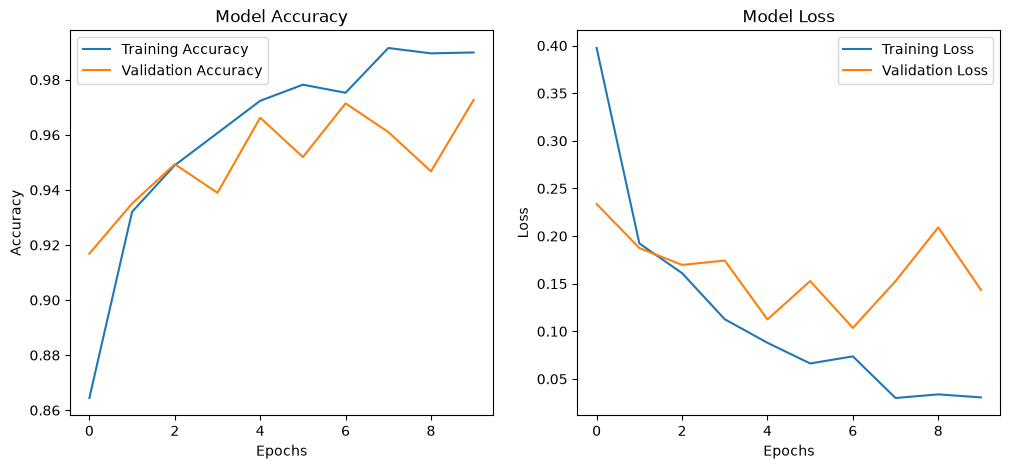

In [13]:
plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()


# Loss
plt.subplot(1,2,2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [14]:
model.save("face_mask_cnn.keras")

In [15]:
import cv2
import numpy as np
from tensorflow import keras

In [31]:
model = keras.models.load_model("face_mask_cnn.keras")

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 28)   │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 28)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        16,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,170,101 (84.57 MB)

 Trainable params: 7,390,033 (28.19 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 14,780,068 (56.38 MB)

In [18]:
print(cv2.__file__)
print(cv2.__version__)
print(hasattr(cv2, "CascadeClassifier"))

/home/lokesh/Loki/Projects/GEN AI/.venv/lib/python3.14/site-packages/cv2/__init__.py
4.14.0
True


In [19]:
%pip list | grep -i opencv

opencv-python             4.14.0.94
Note: you may need to restart the kernel to use updated packages.


In [20]:
print([name for name in dir(cv2) if "Cascade" in name])

['BaseCascadeClassifier', 'CascadeClassifier', 'CascadeClassifier_convert']


In [21]:
print(hasattr(cv2, "objdetect"))

False


In [22]:
face_detector = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

In [23]:
print("Face detector loaded:", not face_detector.empty())

Face detector loaded: True


In [24]:
cap = cv2.VideoCapture(0)

print("Camera available:", cap.isOpened())

cap.release()

Camera available: True


In [29]:

import cv2
import numpy as np

# Open webcam
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Cannot open webcam")

else:
    print("Webcam started!")
    print("Press Q to quit.")

    try:
        while True:

            # Capture continuous frames
            ret, frame = cap.read()

            if not ret:
                print("Cannot read webcam frame")
                break

            # Convert frame to grayscale
            gray = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2GRAY
            )

            # Detect faces
            faces = face_detector.detectMultiScale(
                gray,
                scaleFactor=1.1,
                minNeighbors=5,
                minSize=(30, 30)
            )

            # Process every detected face
            for (x, y, w, h) in faces:

                # Crop face from original frame
                face = frame[y:y+h, x:x+w]

                # Convert BGR to RGB
                face = cv2.cvtColor(
                    face,
                    cv2.COLOR_BGR2RGB
                )

                # Resize to CNN input size
                face = cv2.resize(
                    face,
                    (128, 128)
                )

                # Normalize pixel values
                face = face.astype("float32") / 255.0

                # Add batch dimension
                face = np.expand_dims(face, axis=0)

                # Predict using CNN
                prediction = model.predict(
                    face,
                    verbose=0
                )[0][0]

                # Classification
                if prediction >= 0.5:
                    label = "NO MASK"
                    confidence = prediction * 100
                    color = (0, 0, 255)

                else:
                    label = "MASK"
                    confidence = (1 - prediction) * 100
                    color = (0, 255, 0)

                # Draw rectangle
                cv2.rectangle(
                    frame,
                    (x, y),
                    (x+w, y+h),
                    color,
                    2
                )

                # Display classification
                text = f"{label}: {confidence:.1f}%"

                cv2.putText(
                    frame,
                    text,
                    (x, y-10),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    color,
                    2
                )

            # Display live webcam
            cv2.imshow(
                "Face Mask Detection",
                frame
            )

            # Press Q to quit
            if cv2.waitKey(1) & 0xFF == ord('q'):
                break

    finally:
        cap.release()
        cv2.destroyAllWindows()

        print("Webcam stopped.")


Webcam started!
Press Q to quit.


Cannot read webcam frame
Webcam stopped.


[ WARN:0@1078.515] global cap_v4l.cpp:804 requestBuffers VIDEOIO(V4L2:/dev/video0): failed VIDIOC_REQBUFS: errno=19 (No such device)
